## Initialization

#### Import Library, find available devices

In [2]:
# Initialization code for 3.3 V SiGe LVR Load Regulation Testing.
# This block identifies and initializes the connected SMUs (Source Measure Units).
# If running for the first time, ensure the SMU names are correctly referenced in the subsequent code block.

# This program sweeps VIN for a fixed VREF and measures total quiescent current (IQ) and VOUT. 
# This program sets up a directory for all measurements taken at a specific temperature by prompting the user for the temperature.
# This program creates a .csv file to save the measurements for a VREF in the temperature directory. 

# The setup assumes the use of two SMUs:
# - One dedicated to VIN sweeps.
# - One Sinks a load current and measures VOUT.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as pd              # Importing pandas as pd for data manipulation and analysis
import glob
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from IPython.display import display, clear_output
from datetime import date           # Importing date to read current date
from collections import defaultdict
from scipy.optimize import curve_fit

In [87]:
# Loads ICASL.py from a higher directory
# This file contains functions written by us that can be called with "ICASL.example_function_name"
import importlib.util    # Used to load python files more dynamically (ICASL.py)
quiet=True
current_dir = "."
target_file = "ICASL.py"
target_name = "ICASL"
while True:
    if not quiet: print(current_dir)
    # Check if ICASL is in the current directory
    ICASL_path = os.path.join(current_dir, target_file)
    if not quiet: print(ICASL_path)
    if os.path.isfile(ICASL_path):
        # Loads ICASL.py
        spec = importlib.util.spec_from_file_location(target_name, ICASL_path)
        ICASL = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(ICASL)
        break
    else:
        # Move one level up
        parent_dir = os.path.join(current_dir, "..")
        if not quiet: print(parent_dir)
        if current_dir == parent_dir:  # Reached the root directory
            raise ValueError("ICASL.py not found")
        else:
            current_dir = parent_dir
ICASL.test()

ICASL is loaded!


## Data

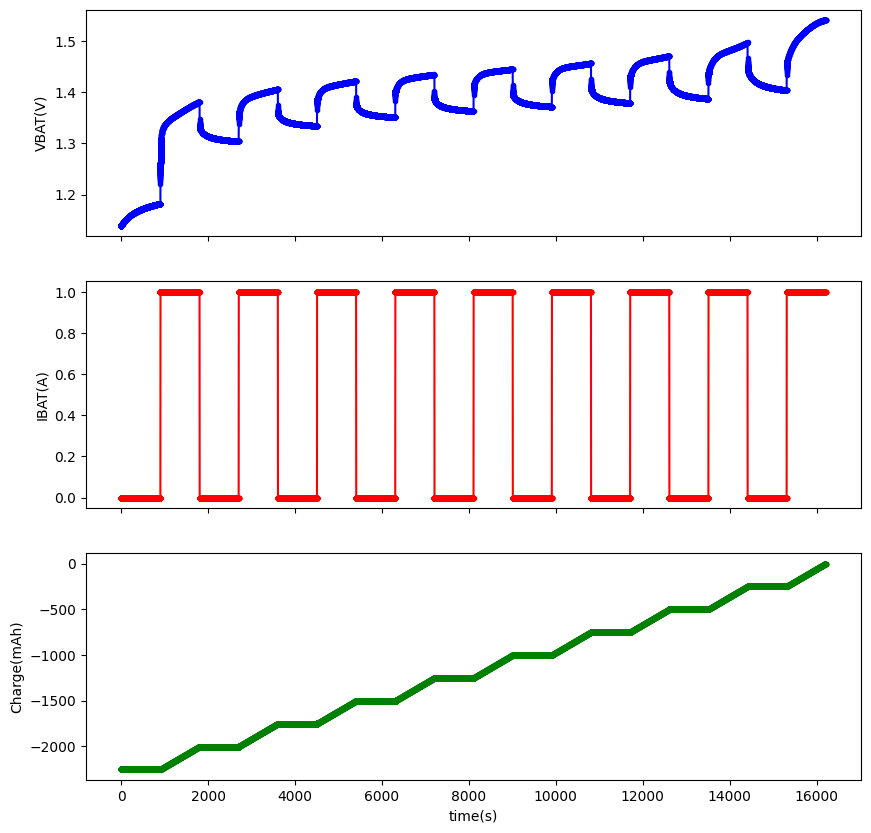

<Figure size 640x480 with 0 Axes>

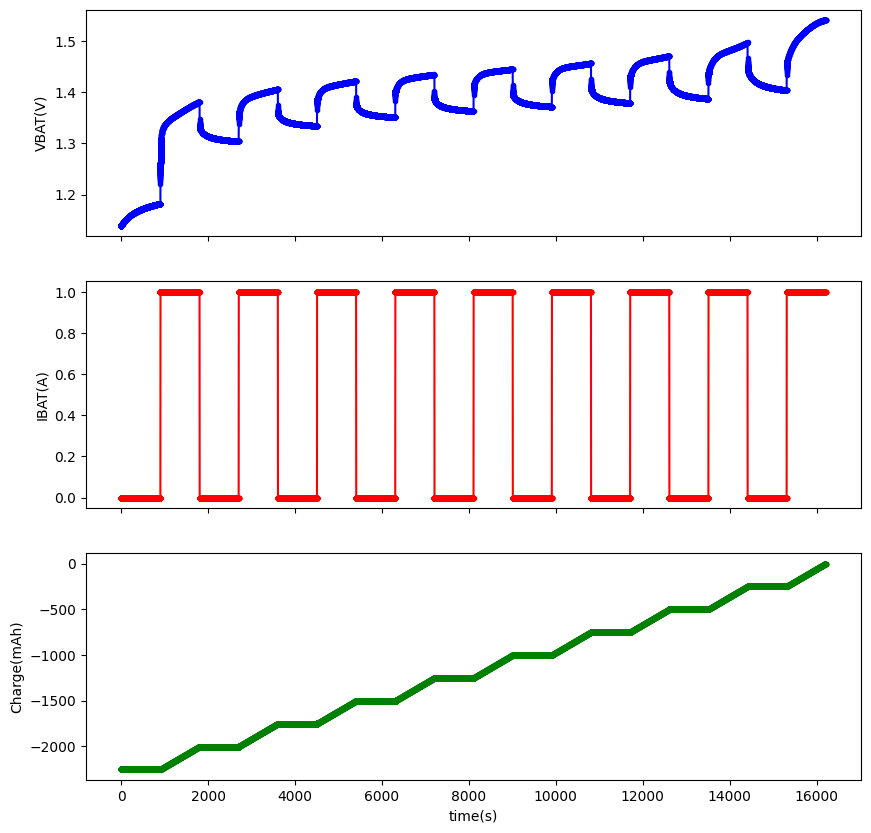

In [121]:
df = pd.read_csv("Charging_with_stops/complete.csv")
#df = pd.read_csv("Discharging_2/complete.csv")
DOD = df["DOD"]
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')

lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(df["times"], df["voltage"])
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(df["times"], df["current"])
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(df["times"], Charge)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()

#ax1.set_ylim(1,1.5)
clear_output(wait = True)

save_dir = os.path.join("Plots")
save_plot = "Charge_cycle.png"
os.makedirs(save_dir, exist_ok=True)
plt.savefig(os.path.join(save_dir, save_plot), dpi=400)

display(fig)

<Figure size 640x480 with 0 Axes>

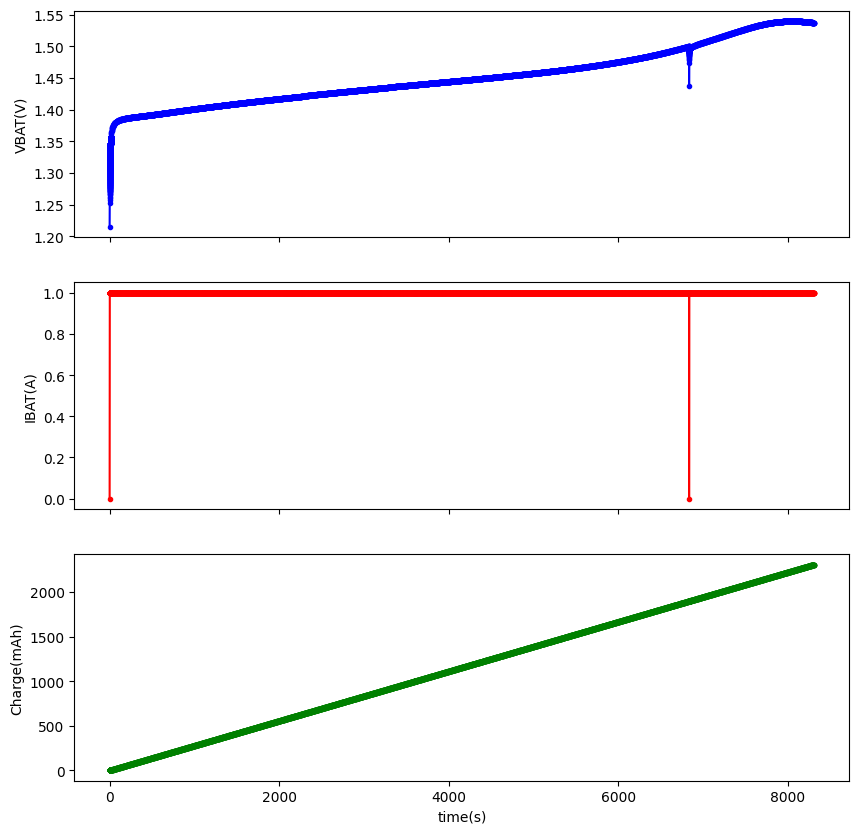

In [ ]:
df = pd.read_csv("Charging_1/complete.csv")
df2 = pd.read_csv("Charging/complete.csv")
DOD = np.concatenate((df["DOD"], df2["DOD"]+df["DOD"][len(df)-1]))
Charge = DOD - DOD[len(DOD)-1]
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize=(10, 10))
ax1.set_ylabel('VBAT(V)')
ax3.set_xlabel('time(s)')
ax2.set_ylabel('IBAT(A)')
ax3.set_ylabel('Charge(mAh)')
times_combined= np.concatenate((df["times"], df2["times"]+df["times"][len(df)-1]))
voltage_combined = np.concatenate((df["voltage"], df2["voltage"]))
current_combined = np.concatenate((df["current"], df2["current"]))

lineV, = ax1.plot([], [], '.-', color='blue')
lineV.set_data(times_combined, voltage_combined)
lineI, = ax2.plot([], [], '.-', color='red')
lineI.set_data(times_combined, current_combined)
lineDOD, = ax3.plot([], [], '.-', color='green')
lineDOD.set_data(times_combined, DOD)
ax1.relim()
ax1.autoscale_view()
ax2.relim()
ax2.autoscale_view()
ax3.relim()
ax3.autoscale_view()
display(fig)
clear_output(wait = True)

save_dir = "Charging_combined"
os.makedirs(save_dir, exist_ok=True)
df = pd.DataFrame({'times': times_combined, 'voltage': voltage_combined, 'current': current_combined, 'DOD':DOD})
df.to_csv(os.path.join(save_dir, f'complete.csv'), index=False)

['Charging_with_stops\\SOC=1.0.csv', 'Charging_with_stops\\SOC=1.1088274018719775.csv', 'Charging_with_stops\\SOC=1.2176657551569987.csv', 'Charging_with_stops\\SOC=1.326398775362323.csv', 'Charging_with_stops\\SOC=1.4351790400120712.csv', 'Charging_with_stops\\SOC=1.544003901557978.csv', 'Charging_with_stops\\SOC=1.6528246230797288.csv', 'Charging_with_stops\\SOC=1.7616439585386696.csv', 'Charging_with_stops\\SOC=1.8703699314492983.csv']
Last Measured OCV: 1.182322 V
Settled OCV: 1.1938270636489554 V
SOC=1.000, R0= -0.013 Ω, R1= 0.009 Ω, R2= 0.046 Ω, C1= 11954.863 F, C2= 14114.368 F, OCV= 1.194 V
Last Measured OCV: 1.304018 V
Settled OCV: 1.3035616208141334 V
SOC=1.109, R0= 0.048 Ω, R1= 0.009 Ω, R2= 0.021 Ω, C1= 2018.697 F, C2= 13319.313 F, OCV= 1.304 V
Last Measured OCV: 1.334247 V
Settled OCV: 1.3338441600104936 V
SOC=1.218, R0= 0.046 Ω, R1= 0.008 Ω, R2= 0.018 Ω, C1= 2285.812 F, C2= 15804.951 F, OCV= 1.334 V
Last Measured OCV: 1.351203 V
Settled OCV: 1.3508057844873997 V
SOC=1.326, 

C:\Users\spnew\AppData\Local\Temp\ipykernel_54408\3849329333.py:98: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


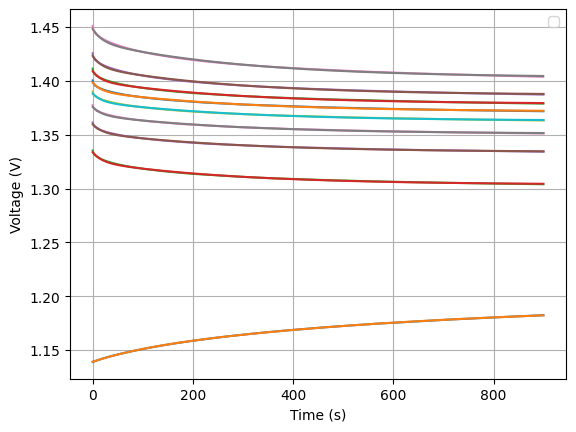

In [54]:
# Select one of these two types:
type = "Charging"
#type = "Discharging"

folder_path = "Charging_with_stops"
file_name = "parameters.csv"
save_name = folder_path+"/"+file_name
file_exists = os.path.isfile(save_name)
if (file_exists): os.remove(save_name) # REMOVES EXISTING FILE TO AVOID APPENDING TO OLD DATA.

file_pattern = os.path.join(folder_path, "SOC*.csv")
file_list = glob.glob(file_pattern)

file_list.sort(key=lambda f: float(os.path.basename(f).replace("SOC=", "").replace(".csv", "")))
if (type=="Discharging"): file_list.reverse()
print(file_list)

for file in file_list:
    df = pd.read_csv(file)
    times1 = df["times"]
    VBAT1 = df["voltage"]
    IBAT1 = df["current"]
    DOD1 = df["DOD"]
    IBAT1=IBAT1.values.tolist()
    VBAT1=VBAT1.values.tolist()

    if (type == "Charging"): index = IBAT1.index(1) # Finds where current turns on
    else:                    index = IBAT1.index(-1) 

    VBAT= VBAT1[20:index]
    IBAT= IBAT1[20:index]
    DOD= DOD1[:index]
    last_measured_OCV= VBAT[-1]
    times= times1[20:index]
    times = times - times[20]

    ### Curve Fitting ###

    def double_exp(t, A, B1, tau1, B2, tau2):
        return A + B1*np.exp(-t/tau1) + B2*np.exp(-t/tau2)

    # Initial parameter guesses
    A0 = VBAT[-1]                  # final voltage
    B1_0 = VBAT[0] - VBAT[-1]        # initial drop
    B2_0 = 0.1 * B1_0
    tau1_0 = 1
    tau2_0 = 50
    p0 = [A0, B1_0, tau1_0, B2_0, tau2_0]

    popt, pcov = curve_fit(double_exp, times, VBAT, p0=p0, maxfev=10000)
    A, B1, tau1, B2, tau2 = popt
    I = 1.0

    settled_OCV = double_exp(100000, *popt)
    print(f"Last Measured OCV: {last_measured_OCV} V")
    print(f"Settled OCV: {settled_OCV} V")

    if (type == "Charging"):
        if (file == file_list[0]):
            R_total = (settled_OCV - VBAT1[index+10]) / IBAT1[index] # Highest SOC might have wrong R0 :(
        else:
            R_total = (settled_OCV - previous_file_charged_OCV) / IBAT1[index]
    elif (type == "Discharging"):
        if (file == file_list[0]):
            R_total = (VBAT1[index+10] - settled_OCV) / IBAT1[index] # Highest SOC might have inaccurate R0 :(
        else:
            R_total = (previous_file_charged_OCV - settled_OCV) / IBAT1[index]

    R1 = abs(B1 / I)
    R2 = abs(B2 / I)
    R0 = abs(R_total) - R1 - R2
    C1 = tau1 / R1
    C2 = tau2 / R2
    print(f"SOC={df['SOC'][0]:.3f}, R0= {R0:.3f} Ω, R1= {R1:.3f} Ω, R2= {R2:.3f} Ω, C1= {C1:.3f} F, C2= {C2:.3f} F, OCV= {settled_OCV:.3f} V")

    previous_file_charged_OCV = VBAT1[-1] # Grabs last OCV at end of charging for next iteration.

    data = [[round(df["SOC"][0],3), round(R0,5), round(R1,5), round(R2,5), int(C1), int(C2), round(settled_OCV,4)]]
    df_new = pd.DataFrame(data, columns=["SOC", "R0", "R1", "R2", "C1", "C2", "OCV"])
    file_exists = os.path.isfile(save_name)
    df_new.to_csv(save_name, mode='a', index=False, header=not file_exists)

    v_fit = double_exp(times, *popt)

    # plt.plot(times, VBAT, label=f"Meas.={df["SOC"][0]:.2f}")
    # plt.plot(times, v_fit, '--', label=f"Fit={df["SOC"][0]:.2f}")
    plt.plot(times, VBAT)
    plt.plot(times, v_fit)

# Reverses the order of rows so SOC goes from 0 to 1.
if (type == "Discharging"):
    df = pd.read_csv(save_name)
    df_reversed = df.iloc[::-1]
    df_reversed.to_csv(save_name, index=False)

plt.xlabel("Time (s)")
plt.ylabel("Voltage (V)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Forces SOC's to be from 0 to 1.
folder_path = "Discharging_2"
#folder_path = "Charging_with_stops"
file_name = "parameters"

df = pd.read_csv(folder_path+"/"+file_name+".csv")
length = len(df["SOC"])
print(df["SOC"])
df["SOC"] = [i/(length-1) for i in range(length)]
print(df["SOC"])
df.to_csv(folder_path+"/"+file_name+"_stretched.csv", index=False)

0    0.130
1    0.238
2    0.347
3    0.456
4    0.565
5    0.674
6    0.782
7    0.891
8    1.000
Name: SOC, dtype: float64
0    0.000
1    0.125
2    0.250
3    0.375
4    0.500
5    0.625
6    0.750
7    0.875
8    1.000
Name: SOC, dtype: float64


In [ ]:
# Applies offset to charging data so OCV matches discharge.
folder_path = "Charging_with_stops"
file_name = "parameters"

# Changes OCV so charge matches discharge.
df = pd.read_csv(folder_path+"/"+file_name+".csv")

df["OCV"] = df["OCV"] - 0.08
print(df["OCV"])
df.to_csv(folder_path+"/"+file_name+"_fudged.csv", index=False)

0    1.1138
1    1.2236
2    1.2538
3    1.2708
4    1.2828
5    1.2914
6    1.2985
7    1.3068
8    1.3230
Name: OCV, dtype: float64


In [119]:
folder_path = "Charging_with_stops"
file_name = "parameters"
df_c = pd.read_csv(folder_path+"/"+file_name+".csv")

folder_path = "Discharging_2"
file_name = "parameters"
df_d = pd.read_csv(folder_path+"/"+file_name+".csv")

fig, ax = ICASL.start_plot("Charging and Discharging Hysteresis Curves", "SOC (%)", "voltage (V)")
ax.plot(df_c["SOC"] * 100, df_c["OCV"], label="Charge OCV", color='red')
ax.plot(df_d["SOC"] * 100, df_d["OCV"], label="Discharge OCV", color='blue')
ax.plot([val * 100 for val in [df_d["SOC"].iloc[-1], df_c["SOC"].iloc[-1]]], [df_d["OCV"].iloc[-1], df_c["OCV"].iloc[-1]], color='purple', linestyle="--")
ax.plot([val * 100 for val in [df_d["SOC"].iloc[0], df_c["SOC"].iloc[0]]], [df_d["OCV"].iloc[0], df_c["OCV"].iloc[0]], color='purple', linestyle="--")

ICASL.finish_plot(fig, ax, save_dir="Plots", save_file="Hysteresis", cm=None, dpi=400)

